# Project 01: Exploratory Data Analysis (EDA) on Titanic
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moryesoham4-SR/Exploratory-Data-Analysis-EDA-on-Titanic/blob/main/titanic_eda.ipynb)

**InternCircle | Data Science & AI**  
**Dataset:** Titanic Passenger Dataset (`seaborn` / `titanic.csv`)

---

## 1. Write Your Questions
Before touching the data, we define three focused questions to guide our exploratory analysis:

1. **Question 1 (Gender):** Did female passengers have a significantly higher survival rate than male passengers, consistent with the "women and children first" evacuation protocol?
2. **Question 2 (Socio-Economic Status / Class):** Did ticket class (`pclass`) significantly determine survival chances? Did passengers in 1st class survive at a much higher rate than those in 3rd class?
3. **Question 3 (Age Demographics):** How did age impact survival across different age groups (Child, Teen, Adult, Middle-aged, Senior)?

## 2. Load and Look
In this step, we load the Titanic dataset, examine its shape, inspect the first few records, view structural data types, and generate summary statistics.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Setup plot styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

# Load Titanic dataset
try:
    df = sns.load_dataset("titanic")
except Exception:
    df = pd.read_csv("titanic.csv")

print("Dataset Shape:", df.shape)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Dataset Shape: (891, 15)


In [2]:
# DataFrame technical information (non-null counts, data types, memory)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 116.9 KB


In [3]:
# Statistical summary of numerical columns
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Column Explanations
| Column Name | Description | Type |
| :--- | :--- | :--- |
| `survived` | Survival binary target (0 = No, 1 = Yes) | Numerical / Binary |
| `pclass` | Passenger Ticket Class (1 = 1st, 2 = 2nd, 3 = 3rd) | Categorical / Ordinal |
| `sex` | Sex of the passenger (`male`, `female`) | Categorical / Nominal |
| `age` | Passenger age in years | Numerical / Continuous |
| `sibsp` | Number of siblings and/or spouses traveling with passenger | Numerical / Discrete |
| `parch` | Number of parents and/or children traveling with passenger | Numerical / Discrete |
| `fare` | Ticket price paid in British pounds | Numerical / Continuous |
| `embarked` | Port of embarkation code (`C` = Cherbourg, `Q` = Queenstown, `S` = Southampton) | Categorical / Nominal |
| `class` | Written ticket class (`First`, `Second`, `Third`) | Categorical / Ordinal |
| `who` | Classification of person (`man`, `woman`, `child`) | Categorical / Nominal |
| `adult_male`| Boolean indicating if passenger is an adult male | Boolean |
| `deck` | Cabin deck floor (`A`, `B`, `C`, `D`, `E`, `F`, `G`) | Categorical |
| `embark_town`| Full embarkation town name | Categorical / Nominal |
| `alive` | String indicator of survival (`yes`, `no`) | Categorical / Binary |
| `alone` | Boolean indicating whether passenger traveled with zero family | Boolean |

## 3. Find Missing Values
We use `df.isna().sum()` to pinpoint which columns contain gaps.

In [4]:
missing_vals = df.isna().sum()
missing_pct = (df.isna().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing_vals, "Percentage (%)": missing_pct})
missing_df[missing_df["Missing Count"] > 0]

,Missing Count,Percentage (%)
age,177,19.87
embarked,2,0.22
deck,688,77.22
embark_town,2,0.22


### Observations on Missing Values:
- **`deck`**: Missing 688 values (77.22%). Over three quarters of the cabin data is unrecorded.
- **`age`**: Missing 177 values (19.87%). Nearly 20% of passengers have unknown ages.
- **`embarked` / `embark_town`**: Missing only 2 values (0.22%).

## 4. Fix Missing Values with Explicit Reasons

We handle each missing column intentionally with clear domain reasoning:

1. **`deck` column -> Dropped (`df.drop(columns=['deck'])`)**  
   *Reason:* With 77.2% missingness, any imputation strategy would fabricate massive amounts of synthetic data and inject significant bias into structural analysis.

2. **`age` column -> Imputed with Grouped Median (`pclass` and `sex`)**  
   *Reason:* Passenger age distributions differed significantly by passenger class (1st class passengers were older and wealthier, while 3rd class had many young emigrant laborers and children) and sex. Imputing the median of each specific `(pclass, sex)` group preserves realistic age structures while remaining robust against extreme outliers.

3. **`embarked` & `embark_town` -> Imputed with Mode**  
   *Reason:* Only 2 records are missing (0.22%). Southampton (`S`) accounts for over 72% of all boardings, so filling with the mode is standard, minimally invasive statistical practice.

In [5]:
# 1. Impute age using class and sex group medians
df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"])["age"].transform("median"))

# 2. Drop the mostly-empty deck column
df = df.drop(columns=["deck"])

# 3. Impute embarked and embark_town with mode
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
if "embark_town" in df.columns:
    df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

# Verification
print("Remaining missing values:")
print(df.isna().sum())

Remaining missing values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


## 5. Check Duplicates and Data Types
We examine duplicates using `df.duplicated().sum()` and inspect column data types.

In [6]:
dup_count = df.duplicated().sum()
print(f"Total duplicate rows: {dup_count}")
print("\nSample of duplicate rows:")
df[df.duplicated(keep=False)].head(6)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
26,0,3,male,25.0,0,0,7.2250,C,Third,man,True,Cherbourg,no,True
28,1,3,female,21.5,0,0,7.8792,Q,Third,woman,False,Queenstown,yes,True
29,0,3,male,25.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
30,0,1,male,40.0,0,0,27.7208,C,First,man,True,Cherbourg,no,True
32,1,3,female,21.5,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True


Total duplicate rows: 118

Sample of duplicate rows:


### Why are there duplicate rows?
Seaborn's version of the Titanic dataset excludes identifying columns like `Name`, `Ticket Number`, and `Cabin Number`. As a result, unrelated individual passengers who shared the exact same class, sex, age, fare, and family size show up as duplicates. Because these rows correspond to **distinct human beings**, they must **not** be dropped, as doing so would artificially shrink the sample and bias survival counts.

In [7]:
# Verify correct data types
print("Data types after verification:")
print(df.dtypes)

Data types after verification:
survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
embark_town        str
alive              str
alone             bool
dtype: object


## 6. Group and Compare Analysis
We analyze survival rates across three key dimensions: **Sex**, **Ticket Class**, and **Age Band**.

### 6.1 Survival Rate by Sex

        count    mean  survival_rate_%
sex                                   
female    314  0.7420            74.20
male      577  0.1889            18.89


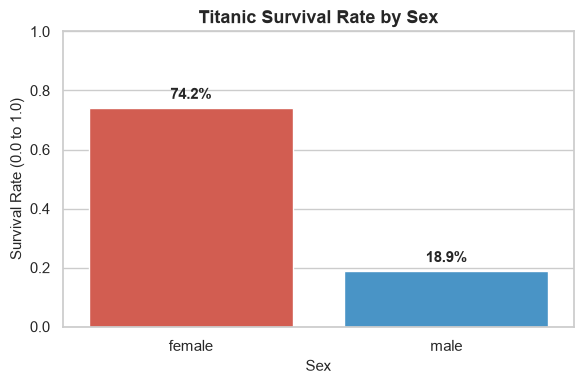

In [8]:
sex_summary = df.groupby("sex")["survived"].agg(["count", "mean"]).round(4)
sex_summary["survival_rate_%"] = (sex_summary["mean"] * 100).round(2)
sex_summary.sort_values(by="mean", ascending=False, inplace=True)
print(sex_summary)

# Bar chart visualization
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=sex_summary.index, y="mean", data=sex_summary.reset_index(), palette=["#e74c3c", "#3498db"], ax=ax)
ax.set_title("Titanic Survival Rate by Sex", fontsize=13, fontweight="bold")
ax.set_ylabel("Survival Rate (0.0 to 1.0)", fontsize=11)
ax.set_xlabel("Sex", fontsize=11)
ax.set_ylim(0, 1.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.tight_layout()
plt.show()

### 6.2 Survival Rate by Ticket Class (`pclass`)

        count    mean  survival_rate_%
pclass                                
1         216  0.6296            62.96
2         184  0.4728            47.28
3         491  0.2424            24.24


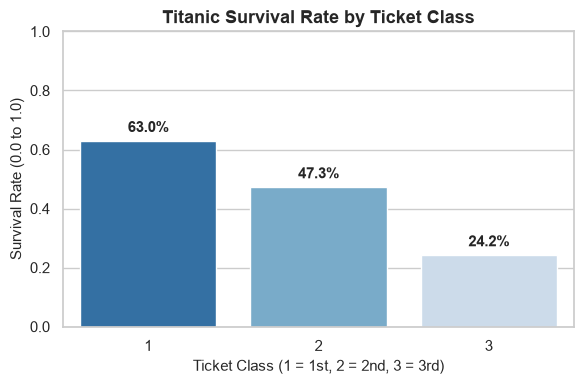

In [9]:
class_summary = df.groupby("pclass")["survived"].agg(["count", "mean"]).round(4)
class_summary["survival_rate_%"] = (class_summary["mean"] * 100).round(2)
class_summary.sort_values(by="mean", ascending=False, inplace=True)
print(class_summary)

# Bar chart visualization
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=class_summary.index, y="mean", data=class_summary.reset_index(), palette="Blues_r", ax=ax)
ax.set_title("Titanic Survival Rate by Ticket Class", fontsize=13, fontweight="bold")
ax.set_ylabel("Survival Rate (0.0 to 1.0)", fontsize=11)
ax.set_xlabel("Ticket Class (1 = 1st, 2 = 2nd, 3 = 3rd)", fontsize=11)
ax.set_ylim(0, 1.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.tight_layout()
plt.show()

### 6.3 Survival Rate by Age Band
We partition passengers into 5 standard life-stage bins using `pd.cut`:
- **Child**: 0–12 years
- **Teen**: 13–18 years
- **Adult**: 19–40 years
- **Middle-aged**: 41–60 years
- **Senior**: 61–100 years

             count    mean  survival_rate_%
age_band                                   
Child           69  0.5797            57.97
Teen            70  0.4286            42.86
Middle-aged    128  0.3906            39.06
Adult          602  0.3605            36.05
Senior          22  0.2273            22.73


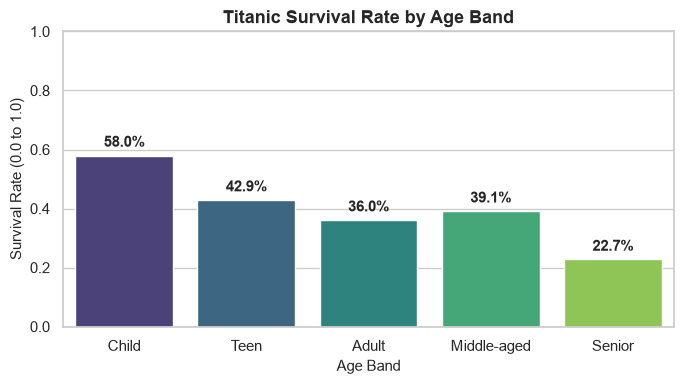

In [10]:
df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"]
)

age_summary = df.groupby("age_band", observed=True)["survived"].agg(["count", "mean"]).round(4)
age_summary["survival_rate_%"] = (age_summary["mean"] * 100).round(2)
age_summary.sort_values(by="mean", ascending=False, inplace=True)
print(age_summary)

# Bar chart visualization
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=age_summary.index, y="mean", data=age_summary.reset_index(), palette="viridis", ax=ax)
ax.set_title("Titanic Survival Rate by Age Band", fontsize=13, fontweight="bold")
ax.set_ylabel("Survival Rate (0.0 to 1.0)", fontsize=11)
ax.set_xlabel("Age Band", fontsize=11)
ax.set_ylim(0, 1.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.tight_layout()
plt.show()

### 6.4 Cross-Tabulation: Class and Sex Combined

sex     female    male
pclass                
1       96.81%  36.89%
2       92.11%  15.74%
3        50.0%  13.54%


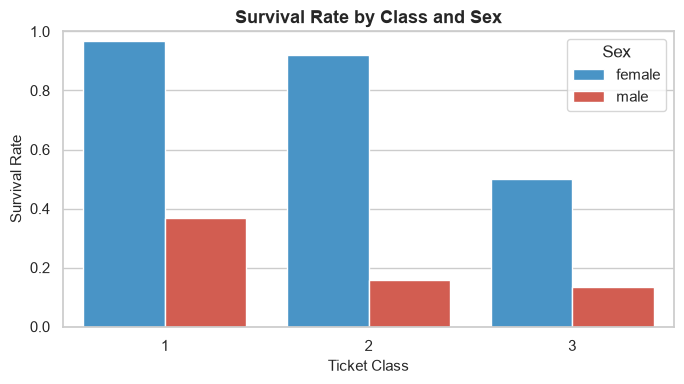

In [11]:
cross_pivot = df.pivot_table(index="pclass", columns="sex", values="survived", aggfunc="mean").round(4)
print((cross_pivot * 100).round(2).astype(str) + "%")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x="pclass", y="survived", hue="sex", data=df, errorbar=None, palette=["#3498db", "#e74c3c"], ax=ax)
ax.set_title("Survival Rate by Class and Sex", fontsize=13, fontweight="bold")
ax.set_ylabel("Survival Rate", fontsize=11)
ax.set_xlabel("Ticket Class", fontsize=11)
ax.set_ylim(0, 1.0)
ax.legend(title="Sex")
plt.tight_layout()
plt.show()

## 7. Answer Your Questions
Here are concise, one-sentence answers to each of the three initial questions with concrete numbers:

1. **Question 1 (Gender):** **Women survived at approximately 74.20% compared with about 18.89% for men**, showing a massive 55.31 percentage point survival advantage due to the strict enforcement of the "women and children first" evacuation protocol.
2. **Question 2 (Ticket Class):** **Ticket class was a decisive survival factor: 62.96% of 1st-class passengers survived, compared with 47.28% in 2nd-class and only 24.24% in 3rd-class**, reflecting structural differences in deck location and emergency access.
3. **Question 3 (Age Band):** **Children (aged 0–12) experienced the highest survival rate at 57.97%, while seniors (aged 61+) had the lowest survival rate at 22.73%**, demonstrating consistent evacuation prioritization for younger passengers over older cohorts.

## 8. Summary of Findings & Verification Checklist

### Submission Checklist:
- [x] **Three clear questions are written at the start.**
- [x] **Missing values are handled and the reasons explained.**
- [x] **Groupings compare survival by at least three factors (Sex, Class, Age Band).**
- [x] **Each question has a one-sentence answer with real numbers.**
- [x] **The notebook runs from top to bottom without errors.**
- [x] **Headings, tables, and notes make it easy to follow.**